# Entrega 1 — Un recomendador que entiende el orden: perfumes
## Transformer (SASRec) vs. líneas base del curso sobre reseñas de perfumes de Amazon

**Grupo 2:** Lucas Torres Baeza · María Jesús Salinas
**Curso:** Aprendizaje no supervisado — Docente: Danilo Gómez Correa

Flujo de la Entrega 1:

`Rubro → Base con tiempo → Secuencias → Líneas base → Transformer → Comparación @K`

**Contenido**
0. Preparación del entorno
1. Datos y secuencias (limpieza, 5-core, exploración, evidencia de orden)
2. Protocolo de evaluación (leave-last-out, HitRate / NDCG / MRR verificadas a mano)
3. Líneas base: popularidad, reglas de asociación e ítem–ítem
4. Transformer: SASRec en PyTorch (3 configuraciones, curvas, parada temprana, prueba una vez)
5. Comparación: métricas, cobertura, costo, segmentos, atención y embeddings
6. Conclusión y exportación

## 0. Preparación del entorno

En Colab: *Entorno de ejecución → Cambiar tipo de entorno → GPU (T4)*. El notebook también corre en CPU, más lento.

In [1]:
import sys
if "google.colab" in sys.modules:
    !pip install -q "mlxtend==0.23.4"

In [2]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)   # avisos internos de Colab (jupyter_client)

import os
import json
import math
import re
import time
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from mlxtend.frequent_patterns import fpgrowth, association_rules
from IPython.display import display

pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_colwidth", 60)
plt.rcParams["figure.dpi"] = 110

AZUL, GRIS, ROJO, DORADO = "#0b1f45", "#52607a", "#c0392b", "#b8860b"

# Semilla fija: partición, negativos, inicialización y orden de los lotes de PyTorch
SEMILLA = 42


def fijar_semilla(s=SEMILLA):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


fijar_semilla()
DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", DISPOSITIVO)

Dispositivo: cuda


## 1. Datos y secuencias

### 1.1 Rubro y base

| | |
|---|---|
| **Rubro** | Perfumes y fragancias |
| **Base** | *Amazon Reviews 2023* (McAuley Lab, UCSD), categorías *Beauty and Personal Care* y *All Beauty*, solo **perfumes** |
| **Enlace** | https://amazon-reviews-2023.github.io · https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023 |
| **Cita** | Hou, Y., Li, J., He, Z., Yan, A., Chen, X. y McAuley, J. (2024). *Bridging Language and Items for Retrieval and Recommendation*. arXiv:2403.03952 |
| **Interacción** | Una **reseña**: (`usuario`, `perfume`, `marca de tiempo`). Se usa como señal implícita: la persona compró y usó ese perfume. |
| **Ítem** | Un perfume (`parent_asin`), con atributos: marca, género/categoría, precio, valoración promedio. |
| **Decisión que apoya** | En una tienda de perfumes en línea: *"según los perfumes que ya tienes, en el orden en que los compraste, este es el que probablemente buscarás después"*. |

**Qué cuenta como perfume.** Un producto entra si su ruta de categorías incluye *Fragrance*, o si su título dice *perfume,
parfum, cologne, eau de, EDT, EDP, body mist, body spray* o *splash* y **no** dice *fragrance-free* ni *unscented*. Un primer
filtro más amplio dejaba pasar cremas y protectores solares "fragrance-free" (≈ 27 % de los ítems); con ellos la base superaba
las 50.000 interacciones, pero dejaba de ser una base de perfumes.

**Excepción autorizada.** Tras el 5-core la base queda con ≈ 39.000 interacciones: cumple con holgura los mínimos de usuarios
(≥ 2.000) y de ítems (≥ 500), pero no el de 50.000 interacciones. El profesor autorizó trabajar con esta base de solo perfumes.

### 1.2 Carga

La descarga se hace una sola vez (celda siguiente) y queda guardada en Drive como parquet: dos archivos por categoría de Amazon.

In [3]:
# Carpeta con los parquet (en Colab: Google Drive)
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    CARPETA = "/content/drive/MyDrive"
else:
    CARPETA = os.environ.get("CARPETA_DATOS", ".")

# Un par de archivos (metadatos, reseñas) por categoría de Amazon
FUENTES = {
    "Beauty_and_Personal_Care": "amazon_perfumes",
    "All_Beauty": "amazon_allbeauty_perfumes",
}
RUTAS = {cat: (os.path.join(CARPETA, f"{pre}_meta.parquet"), os.path.join(CARPETA, f"{pre}_interacciones.parquet"))
         for cat, pre in FUENTES.items()}
for cat, (rm, ri) in RUTAS.items():
    print(f"{cat:26s} ¿existen los parquet? {os.path.exists(rm)} {os.path.exists(ri)}")

Mounted at /content/drive


Beauty_and_Personal_Care   ¿existen los parquet? True True
All_Beauty                 ¿existen los parquet? True True


In [4]:
# Descarga (solo si faltan los parquet). Beauty and Personal Care toma ~15-20 min en Colab; All Beauty ~1 min.
import requests

BASE_HF = "https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/resolve/main/raw/"
PALABRAS_PERFUME = re.compile(r"perfume|parfum|cologne|eau de|\bedt\b|\bedp\b|body mist|body spray|fragrance mist|splash", re.I)
SIN_AROMA = re.compile(r"fragrance[- ]?free|unscented", re.I)
CAMPOS = ["parent_asin", "title", "store", "categories", "average_rating", "rating_number", "price"]


def lineas(url):
    # Lee el archivo línea a línea sin guardarlo completo en disco
    with requests.get(url, stream=True) as r:
        r.raise_for_status()
        for l in r.iter_lines():
            if l:
                yield l


def es_perfume(categorias, titulo):
    titulo = titulo or ""
    return ("Fragrance" in " ".join(categorias if categorias is not None else [])
            or (bool(PALABRAS_PERFUME.search(titulo)) and not SIN_AROMA.search(titulo)))


def descargar(cat, ruta_meta, ruta_inter):
    meta = []
    for l in lineas(BASE_HF + f"meta_categories/meta_{cat}.jsonl"):
        d = json.loads(l)
        if es_perfume(d.get("categories"), d.get("title")):
            meta.append({k: d.get(k) for k in CAMPOS})
    meta = pd.DataFrame(meta)
    meta["price"] = meta["price"].astype(str)          # mezcla números y textos ("from 28.00")
    asins = set(meta["parent_asin"])
    patron = re.compile(rb'"parent_asin":\s*"([^"]+)"')
    filas = []
    for l in lineas(BASE_HF + f"review_categories/{cat}.jsonl"):
        m = patron.search(l)
        if m and m.group(1).decode() in asins:
            d = json.loads(l)
            filas.append((d["user_id"], d["parent_asin"], d["rating"], d["timestamp"]))
    pd.DataFrame(filas, columns=["usuario", "item", "rating", "timestamp"]).to_parquet(ruta_inter)
    meta.to_parquet(ruta_meta)


for cat, (rm, ri) in RUTAS.items():
    if not (os.path.exists(rm) and os.path.exists(ri)):
        print("Descargando", cat, "...")
        descargar(cat, rm, ri)

# Se juntan ambas categorías y se aplica el filtro de perfume a todos los productos
meta = pd.concat([pd.read_parquet(rm) for rm, _ in RUTAS.values()]).drop_duplicates("parent_asin")
inter = pd.concat([pd.read_parquet(ri) for _, ri in RUTAS.values()], ignore_index=True)
n_productos = len(meta)
meta = meta[[es_perfume(c, t) for c, t in zip(meta["categories"], meta["title"])]]
inter = inter[inter["item"].isin(set(meta["parent_asin"]))]
print(f"Productos descargados: {n_productos:,} | son perfumes: {len(meta):,} | reseñas de perfumes: {len(inter):,}".replace(",", "."))
inter.head()

Productos descargados: 70.241 | son perfumes: 63.656 | reseñas de perfumes: 1.171.594


,usuario,item,rating,timestamp
1,AG2L7H23R5LLKDKLBEF2Q3L2MVDA,B000XE8XO8,5.0000,1593933889664
3,AFEIN7QWSQ6EFW45LKD7ZOCSMLGQ,B08TRBZCSK,4.0000,1632177664091
4,AH6CATODIVPVUOJEWHRSRCSKAOHA,B0BCF5SDYW,5.0000,1667840230506
6,AHWRKUZUZNWALPR3HG6H3QBFEBDA,B00KF3L2O0,5.0000,1439652687000
7,AH6PLOGWYIVIWLJTY756BHNFD4YA,B00018KV1E,1.0000,1413544433000


### 1.3 Limpieza y filtro 5-core

1. Se eliminan filas con usuario, ítem o fecha nulos.
2. **Duplicados**: si una persona reseñó el mismo perfume más de una vez, se conserva la **primera** vez (la compra original).
3. Se pasa la marca de tiempo (milisegundos) a fecha.
4. **Filtro 5-core iterativo**: cada usuario con ≥ 5 perfumes y cada perfume con ≥ 5 usuarios. Se repite hasta que no cambie,
   porque sacar perfumes puede dejar usuarios con menos de 5 y viceversa.

In [5]:
n0 = len(inter)
inter = inter.dropna(subset=["usuario", "item", "timestamp"])
inter = inter.sort_values(["timestamp", "item"]).drop_duplicates(["usuario", "item"], keep="first")
inter["fecha"] = pd.to_datetime(inter["timestamp"], unit="ms")
print(f"Reseñas originales: {n0:,} | sin nulos ni duplicados: {len(inter):,}".replace(",", "."))


RONDAS_5CORE = [{"ronda": 0, "interacciones": len(inter), "usuarios": inter["usuario"].nunique(),
                  "perfumes": inter["item"].nunique()}]


def cinco_core(df, k=5):
    ronda = 0
    while True:
        ronda += 1
        cu = df["usuario"].map(df["usuario"].value_counts())
        ci = df["item"].map(df["item"].value_counts())
        nuevo = df[(cu >= k) & (ci >= k)]
        RONDAS_5CORE.append({"ronda": ronda, "interacciones": len(nuevo), "usuarios": nuevo["usuario"].nunique(),
                             "perfumes": nuevo["item"].nunique()})
        print(f"  ronda {ronda}: {len(nuevo):,} interacciones | {nuevo['usuario'].nunique():,} usuarios | "
              f"{nuevo['item'].nunique():,} perfumes".replace(",", "."))
        if len(nuevo) == len(df):
            return nuevo.copy()
        df = nuevo


datos = cinco_core(inter)
resumen = pd.Series({
    "Interacciones": len(datos),
    "Usuarios": datos["usuario"].nunique(),
    "Perfumes": datos["item"].nunique(),
})
print()
print(resumen.to_string())
print(f"Mínimos: usuarios ≥ 2.000 → {resumen['Usuarios'] >= 2_000} | perfumes ≥ 500 → {resumen['Perfumes'] >= 500} | "
      f"interacciones ≥ 50.000 → {resumen['Interacciones'] >= 50_000} (excepción autorizada por el profesor)")

Reseñas originales: 1.171.594 | sin nulos ni duplicados: 1.171.421


  ronda 1: 80.103 interacciones | 11.489 usuarios | 13.321 perfumes
  ronda 2: 59.042 interacciones | 10.064 usuarios | 3.347 perfumes
  ronda 3: 46.718 interacciones | 6.490 usuarios | 3.141 perfumes


  ronda 4: 43.836 interacciones | 6.358 usuarios | 2.418 perfumes
  ronda 5: 41.215 interacciones | 5.701 usuarios | 2.383 perfumes
  ronda 6: 40.445 interacciones | 5.669 usuarios | 2.211 perfumes
  ronda 7: 39.661 interacciones | 5.483 usuarios | 2.199 perfumes
  ronda 8: 39.399 interacciones | 5.470 usuarios | 2.145 perfumes


  ronda 9: 39.163 interacciones | 5.416 usuarios | 2.140 perfumes
  ronda 10: 39.112 interacciones | 5.414 usuarios | 2.129 perfumes
  ronda 11: 39.068 interacciones | 5.404 usuarios | 2.128 perfumes
  ronda 12: 39.052 interacciones | 5.402 usuarios | 2.126 perfumes
  ronda 13: 39.032 interacciones | 5.398 usuarios | 2.125 perfumes
  ronda 14: 39.032 interacciones | 5.398 usuarios | 2.125 perfumes

Interacciones    39032
Usuarios          5398
Perfumes          2125
Mínimos: usuarios ≥ 2.000 → True | perfumes ≥ 500 → True | interacciones ≥ 50.000 → False (excepción autorizada por el profesor)


### 1.4 Atributos de los perfumes

De los metadatos se extraen **marca** (`store`), **género**, **precio** y **valoración promedio**. Se usan en la
exploración, en los segmentos y en el gráfico de embeddings.

**Género (corregido tras la Entrega 1).** La primera versión revisaba *Women → Men → Unisex* y no detectó ningún perfume
unisex. Ahora se revisa **primero *Unisex***, se marca como unisex un producto cuya ruta o título nombra ambos géneros, y si
la ruta de categorías no dice nada se usa el título (*for women*, *pour homme*, *unisex*…). `\bmen` evita confundir *men*
dentro de *women*.

In [6]:
MUJER = re.compile(r"\bwom[ae]n'?s?\b|\bfor her\b|\bpour femme\b|\bfemme\b|\bladies\b", re.I)
HOMBRE = re.compile(r"\bm[ae]n'?s?\b|\bfor him\b|\bpour homme\b|\bhomme\b|\bcologne for men\b", re.I)


def genero_texto(texto):
    if re.search(r"\bunisex\b", texto, re.I):
        return "Unisex"
    w, m = bool(MUJER.search(texto)), bool(HOMBRE.search(texto))
    if w and m:
        return "Unisex"
    return "Mujer" if w else "Hombre" if m else None


def genero(cats, titulo):
    # 1.º la ruta de categorías de Amazon; si no informa, el título
    ruta = " ".join(cats) if cats is not None else ""
    return genero_texto(ruta) or genero_texto(titulo or "") or "Sin dato"


def a_precio(x):
    # El precio viene como texto: "28.00", "from 28.00", "None"...
    m = re.search(r"\d+(?:\.\d+)?", str(x).replace(",", ""))
    return float(m.group()) if m else np.nan


atributos = meta.drop_duplicates("parent_asin").set_index("parent_asin")
atributos = pd.DataFrame({
    "titulo": atributos["title"].fillna("(sin título)").str.slice(0, 90),
    "marca": atributos["store"].fillna("(sin marca)").str.strip(),
    "genero": [genero(list(c) if c is not None else [], t) for c, t in zip(atributos["categories"], atributos["title"])],
    "precio": atributos["price"].apply(a_precio),
    "valoracion": atributos["average_rating"],
})
atributos = atributos.loc[atributos.index.isin(datos["item"].unique())]
print(atributos["genero"].value_counts().to_string())
print(f"\nMarcas distintas: {atributos['marca'].nunique()} | perfumes con precio: {atributos['precio'].notna().mean():.0%}")
atributos.head()

genero
Mujer       1085
Hombre       948
Sin dato      80
Unisex        12

Marcas distintas: 490 | perfumes con precio: 76%


,titulo,marca,genero,precio,valoracion
parent_asin,,,,,
B06X6JKN8X,Can Can Burlesque For Women 8.0 oz Body Spray By Paris H...,Paris Hilton,Mujer,12.4800,4.6000
B09KTCJD6W,RACHEL ZOE Fearless Set - Set of 3 Eau de Parfum Sprays ...,RACHEL ZOE,Mujer,54.5800,4.5000
B0BD21ND22,Maison d'Orient MUSK TAHARA 12mL Artisanal Hand Crafted ...,Maison d'Orient,Mujer,21.9500,4.3000
B01H6EBRNQ,"CLEAN Eau de Parfum Spray, 2.14 Fl Oz",(sin marca),Mujer,NaN,4.5000
B07TCYRK5J,Bath & Body Works Endless Weekend Fine Fragrance Body Mi...,Bath & Body Works,Mujer,17.9000,4.6000


### 1.5 Secuencias por usuario

Cada usuario queda como una **secuencia ordenada por fecha**. Los perfumes se numeran desde 1: el **índice 0 es relleno**
(*padding*), que se usa para que todas las secuencias de un lote tengan el mismo largo.

In [7]:
# Índices: perfume → 1..n (0 = relleno); usuario → 0..m-1
items_orden = datos["item"].value_counts().index           # más popular = índice 1
item2idx = {a: i + 1 for i, a in enumerate(items_orden)}
idx2item = {i: a for a, i in item2idx.items()}
N_ITEMS = len(item2idx)

datos["idx"] = datos["item"].map(item2idx)
datos = datos.sort_values(["usuario", "timestamp", "idx"])
secuencias = datos.groupby("usuario")["idx"].apply(list)
fechas = datos.groupby("usuario")["fecha"].apply(list)
usuarios = secuencias.index.tolist()

largos = secuencias.apply(len)
print(f"Usuarios: {len(secuencias):,} | perfumes: {N_ITEMS:,}".replace(",", "."))
print(f"Largo de la secuencia: media {largos.mean():.1f}, mediana {largos.median():.0f}, máx {largos.max()}")
print("Ejemplo:", [atributos.loc[idx2item[i], "marca"] for i in secuencias.iloc[0]])

Usuarios: 5.398 | perfumes: 2.125
Largo de la secuencia: media 7.2, mediana 6, máx 115
Ejemplo: ['Issey Miyake', 'Nautica', '(sin marca)', 'CARTIER', 'ARMAF', 'Armaf', 'Dolce & Gabbana']


### 1.6 Exploración

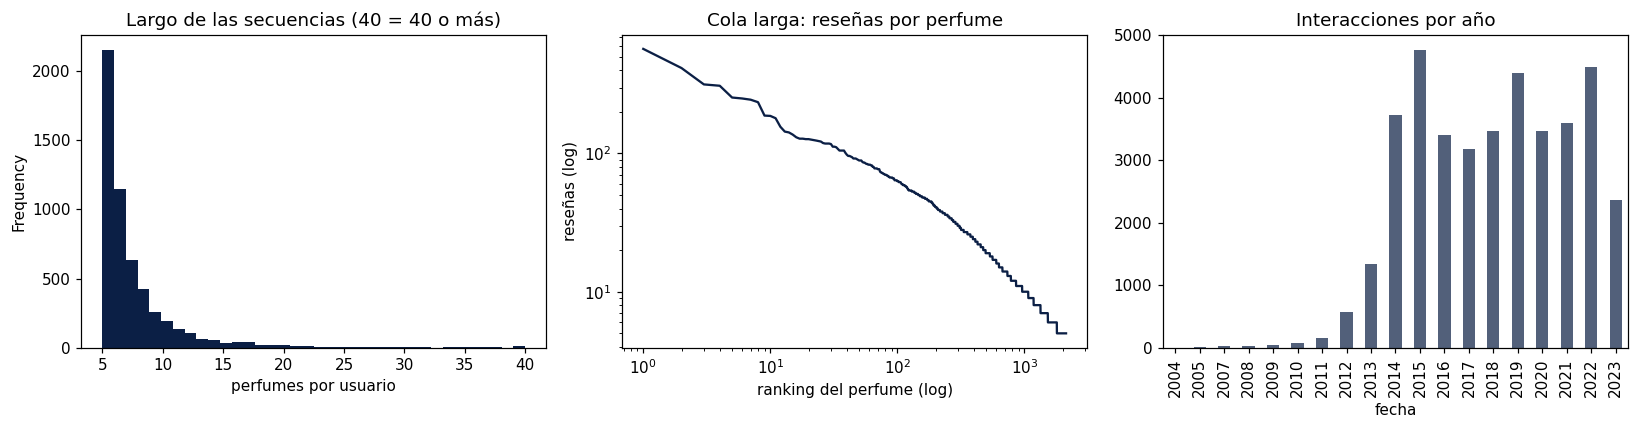

Densidad: 0.3403% | dispersión: 99.6597%
El 20 % de perfumes más reseñados concentra el 59% de las interacciones
Periodo: 2004-08 a 2023-09


In [8]:
n_u, n_i, n_x = len(secuencias), N_ITEMS, len(datos)
densidad = n_x / (n_u * n_i)
pop_item = datos["idx"].value_counts()

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
largos.clip(upper=40).plot.hist(bins=36, ax=ax[0], color=AZUL)
ax[0].set_title("Largo de las secuencias (40 = 40 o más)")
ax[0].set_xlabel("perfumes por usuario")

orden_pop = pop_item.sort_values(ascending=False).values
ax[1].plot(np.arange(1, len(orden_pop) + 1), orden_pop, color=AZUL)
ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_title("Cola larga: reseñas por perfume")
ax[1].set_xlabel("ranking del perfume (log)"); ax[1].set_ylabel("reseñas (log)")

datos["fecha"].dt.year.value_counts().sort_index().plot.bar(ax=ax[2], color=GRIS)
ax[2].set_title("Interacciones por año")
plt.tight_layout(); plt.show()

top20 = pop_item.head(int(0.2 * n_i)).sum() / n_x
print(f"Densidad: {densidad:.4%} | dispersión: {1 - densidad:.4%}")
print(f"El 20 % de perfumes más reseñados concentra el {top20:.0%} de las interacciones")
print(f"Periodo: {datos['fecha'].min():%Y-%m} a {datos['fecha'].max():%Y-%m}")

### 1.7 ¿Importa el orden? Evidencia

Si el orden no importara, el perfume siguiente de una persona se parecería al anterior **igual que cualquier otro** perfume
de su propio historial. Comparamos la probabilidad de que dos perfumes **consecutivos** compartan marca (o género) con la de
dos perfumes tomados **al azar** del mismo historial. Si los consecutivos se parecen más, la secuencia tiene información
que una "bolsa de ítems" pierde.

In [9]:
marca_de = {item2idx[a]: atributos.loc[a, "marca"] for a in item2idx}
genero_de = {item2idx[a]: atributos.loc[a, "genero"] for a in item2idx}
rng = np.random.default_rng(SEMILLA)


def comparar(attr):
    consecutivos, azar = [], []
    for s in secuencias:
        for a, b in zip(s[:-1], s[1:]):
            consecutivos.append(attr[a] == attr[b])
        for _ in range(len(s) - 1):                         # mismo número de pares, al azar
            a, b = rng.choice(s, 2, replace=False)
            azar.append(attr[a] == attr[b])
    return np.mean(consecutivos), np.mean(azar)


evidencia = pd.DataFrame([
    ("Misma marca", *comparar(marca_de)),
    ("Mismo género", *comparar(genero_de)),
], columns=["atributo", "pares consecutivos", "pares al azar (mismo usuario)"])
evidencia["razón"] = evidencia["pares consecutivos"] / evidencia["pares al azar (mismo usuario)"]
evidencia

,atributo,pares consecutivos,pares al azar (mismo usuario),razón
0,Misma marca,0.1021,0.0755,1.3525
1,Mismo género,0.6932,0.6732,1.0298


### Hallazgos de los datos

1. **Base muy dispersa.** Hay 39.032 interacciones entre 5.398 usuarios y 2.125 perfumes. La densidad es **0,34 %**: de cada 300 pares usuario–perfume posibles, existe uno solo. Por eso todas las métricas de la sección 5 son bajas en términos absolutos.
2. **Historiales cortos.** La mediana es de **6 perfumes por persona** y el promedio de 7,2. El 95 % tiene 14 o menos, que es el largo máximo que lee SASRec; el máximo llega a 115.
3. **Cola larga marcada.** El 20 % de perfumes más reseñados concentra el **59 %** de las interacciones. Los más populares son clásicos masculinos de precio medio: Nautica Voyage, Versace Man Eau Fraîche y Armaf Club de Nuit.
4. **El orden importa, sobre todo en la marca.** Dos perfumes **consecutivos** comparten marca el **10,2 %** de las veces; dos tomados al azar del mismo historial, el 7,5 %, es decir, **1,35 veces más**. Después de comprar un perfume, la persona tiende a seguir con la misma casa, y esa información se pierde si el historial se trata como una canasta sin orden. Con el género casi no hay diferencia (1,03), porque cada persona compra casi siempre del mismo género.
5. **Periodo largo.** Las reseñas van de agosto de 2004 a septiembre de 2023, con el grueso entre 2014 y 2022.

**Calidad de los datos.** Con la función de género corregida (unisex primero, título como respaldo) quedan 1.085 perfumes de mujer, 948 de hombre, 12 unisex y 80 sin dato (3,8 %). El filtro de perfumes deja pasar unos 20 accesorios (atomizadores, frascos para aceites), que suman solo el 0,3 % de las interacciones de entrenamiento; se dejan para no alterar la base inscrita y se declaran como limitación.

## 2. Protocolo de evaluación

**Leave-last-out por usuario**, igual para todos los modelos:

| Parte | Qué contiene | Para qué |
|---|---|---|
| Entrenamiento | todos los perfumes menos los 2 últimos | minar reglas, popularidad, similitudes y entrenar SASRec |
| Validación | el **penúltimo** perfume (con el historial anterior) | elegir configuración y parada temprana |
| Prueba | el **último** perfume (con todo el historial anterior) | se reporta **una sola vez** al final |

Cada modelo ordena **todo el catálogo** (excluyendo los perfumes que el usuario ya tiene) y se busca la posición $r_u$ del
perfume oculto:

$$HitRate@K = \frac{1}{|U|}\sum_u \mathbb{1}[r_u \le K] \qquad NDCG@K = \frac{1}{|U|}\sum_u \frac{\mathbb{1}[r_u \le K]}{\log_2(r_u + 1)} \qquad MRR@K = \frac{1}{|U|}\sum_u \frac{\mathbb{1}[r_u \le K]}{r_u}$$

In [10]:
# Partición leave-last-out
entren = {u: s[:-2] for u, s in secuencias.items()}
valid = {u: (s[:-2], s[-2]) for u, s in secuencias.items()}     # (historial, objetivo)
prueba = {u: (s[:-1], s[-1]) for u, s in secuencias.items()}
print(f"Interacciones de entrenamiento: {sum(len(s) for s in entren.values()):,}".replace(",", "."))
print(f"Usuarios en validación y prueba: {len(valid):,}".replace(",", "."))

KS = [5, 10, 20]
K_MAX = max(KS)


def metricas(rankings, objetivos):
    # rankings: lista de listas top-K_MAX; objetivos: perfume oculto de cada usuario
    fila = {}
    pos = []
    for lista, obj in zip(rankings, objetivos):
        lista = list(lista)
        pos.append(lista.index(obj) + 1 if obj in lista else 0)   # 0 = no aparece
    pos = np.array(pos)
    for k in KS:
        dentro = (pos > 0) & (pos <= k)
        fila[f"HR@{k}"] = dentro.mean()
        fila[f"NDCG@{k}"] = np.where(dentro, 1 / np.log2(np.maximum(pos, 1) + 1), 0).mean()
        fila[f"MRR@{k}"] = np.where(dentro, 1 / np.maximum(pos, 1), 0).mean()
    return fila, pos


def evaluar(recomendador, conjunto, k=K_MAX):
    # recomendador(historial, k) -> lista de k perfumes (sin los del historial)
    rankings, objetivos = [], []
    for u in usuarios:
        hist, obj = conjunto[u]
        rankings.append(recomendador(hist, k))
        objetivos.append(obj)
    return metricas(rankings, objetivos), rankings

Interacciones de entrenamiento: 28.236
Usuarios en validación y prueba: 5.398


### 2.1 Verificación a mano en un usuario

Tomamos un usuario, una lista de recomendación cualquiera (aquí la de popularidad) y calculamos las métricas a mano para
comprobar que la función `metricas` hace lo que dicen las fórmulas.

In [11]:
# Popularidad (se define formalmente en la sección 3; aquí solo para la verificación)
conteo_entren = pd.Series([i for s in entren.values() for i in s]).value_counts()


def rec_popularidad(hist, k):
    vistos = set(hist)
    return [i for i in conteo_entren.index if i not in vistos][:k]


# Elegimos un usuario cuyo perfume oculto aparezca en el top 20 de popularidad
for u in usuarios:
    hist, obj = prueba[u]
    lista = rec_popularidad(hist, K_MAX)
    if obj in lista[1:]:
        break

r = lista.index(obj) + 1
print(f"Usuario de ejemplo | perfume oculto: {idx2item[obj]} ({marca_de[obj]}) | posición r = {r}")
for k in KS:
    hr = 1 if r <= k else 0
    ndcg = hr / math.log2(r + 1)
    mrr = hr / r
    print(f"  K={k:2d}: HitRate = {hr} | NDCG = 1/log2({r}+1) = {ndcg:.4f} | MRR = 1/{r} = {mrr:.4f}"
          if hr else f"  K={k:2d}: no aparece → HitRate = NDCG = MRR = 0")

auto, _ = metricas([lista], [obj])
print("\nCon la función metricas():", {k: round(v, 4) for k, v in auto.items() if k.endswith(("@5", "@10", "@20"))})
VERIF = {"r": r, "objetivo": idx2item[obj], "marca": marca_de[obj],
         "NDCG@5": 1 / math.log2(r + 1) if r <= 5 else 0.0, "MRR@5": 1 / r if r <= 5 else 0.0}

Usuario de ejemplo | perfume oculto: B072F746SZ (Perry Ellis) | posición r = 5
  K= 5: HitRate = 1 | NDCG = 1/log2(5+1) = 0.3869 | MRR = 1/5 = 0.2000
  K=10: HitRate = 1 | NDCG = 1/log2(5+1) = 0.3869 | MRR = 1/5 = 0.2000
  K=20: HitRate = 1 | NDCG = 1/log2(5+1) = 0.3869 | MRR = 1/5 = 0.2000

Con la función metricas(): {'HR@5': np.float64(1.0), 'NDCG@5': np.float64(0.3869), 'MRR@5': np.float64(0.2), 'HR@10': np.float64(1.0), 'NDCG@10': np.float64(0.3869), 'MRR@10': np.float64(0.2), 'HR@20': np.float64(1.0), 'NDCG@20': np.float64(0.3869), 'MRR@20': np.float64(0.2)}


## 3. Líneas base

Todas se construyen **solo con las secuencias de entrenamiento** y excluyen de la lista los perfumes que el usuario ya tiene.

1. **Popularidad**: los perfumes más reseñados.
2. **Reglas de asociación** (Certamen 2): cada secuencia de entrenamiento es una **canasta**; se minan reglas con FP-Growth,
   se activan las que tienen el antecedente en el historial y se ordenan por **lift**; se completa con populares. Los
   umbrales de **soporte** (canastas mínimas) y **confianza** se eligen con **NDCG@10 de validación** en una grilla de 5 × 5,
   igual que las configuraciones de SASRec.
3. **Ítem–ítem con coseno**: similitud coseno entre perfumes según quién los reseñó; el puntaje suma la similitud con los
   **últimos** perfumes del historial, con más peso al más reciente.

In [12]:
# 3.1 Popularidad: ya definida (rec_popularidad). Evaluación en validación:
(m_pop_val, _), _ = evaluar(rec_popularidad, valid)
pd.Series(m_pop_val).to_frame("Popularidad (validación)").T

,HR@5,NDCG@5,MRR@5,HR@10,NDCG@10,MRR@10,HR@20,NDCG@20,MRR@20
Popularidad (validación),0.0522,0.0344,0.0286,0.0823,0.0440,0.0325,0.1191,0.0533,0.0350


In [13]:
# 3.2 Reglas de asociación sobre las canastas de entrenamiento (como en el Certamen 2)
M = np.zeros((len(usuarios), N_ITEMS), dtype=bool)          # usuarios × perfumes (solo entrenamiento)
for f, u in enumerate(usuarios):
    M[f, np.array(entren[u], dtype=int) - 1] = True
canasta = pd.DataFrame(M, columns=range(1, N_ITEMS + 1))
canasta = canasta.loc[:, canasta.any()]

# Umbrales elegidos en VALIDACIÓN (como SASRec): se mina una vez con el soporte más bajo de la grilla y luego se filtra
t0 = time.perf_counter()
frec_todos = fpgrowth(canasta, min_support=2 / len(usuarios), use_colnames=True, max_len=2)
reglas_todas = association_rules(frec_todos, metric="confidence", min_threshold=0.01)
reglas_todas = reglas_todas[(reglas_todas["consequents"].apply(len) == 1) & (reglas_todas["lift"] > 1)].copy()
reglas_todas["ante"] = reglas_todas["antecedents"].apply(lambda x: next(iter(x)))
reglas_todas["cons"] = reglas_todas["consequents"].apply(lambda x: next(iter(x)))
reglas_todas["canastas"] = (reglas_todas["support"] * len(usuarios)).round().astype(int)
print(f"Minado inicial (≥ 2 canastas, confianza ≥ 0,01): {len(reglas_todas)} reglas en {time.perf_counter() - t0:.1f} s")


def preparar_reglas(min_canastas, min_conf):
    r = reglas_todas[(reglas_todas["canastas"] >= min_canastas) & (reglas_todas["confidence"] >= min_conf)]
    indice = {}
    for a, c, l in zip(r["ante"], r["cons"], r["lift"]):
        indice.setdefault(a, {})
        indice[a][c] = max(l, indice[a].get(c, 0))
    return r, indice


def hacer_rec_reglas(indice):
    def rec(hist, k):
        vistos = set(hist)
        puntaje = {}
        for a in vistos:
            for c, l in indice.get(a, {}).items():
                if c not in vistos:
                    puntaje[c] = max(l, puntaje.get(c, 0))     # mejor lift que lo activa
        lista = [c for c, _ in sorted(puntaje.items(), key=lambda x: (-x[1], x[0]))][:k]
        for i in conteo_entren.index:                         # respaldo: populares
            if len(lista) >= k:
                break
            if i not in vistos and i not in lista:
                lista.append(i)
        return lista
    return rec


grilla_reglas = []
for min_canastas in [2, 3, 5, 10, 20]:
    for min_conf in [0.01, 0.05, 0.10, 0.20, 0.30]:
        r, indice = preparar_reglas(min_canastas, min_conf)
        (m, _), _ = evaluar(hacer_rec_reglas(indice), valid)
        grilla_reglas.append({"soporte (canastas)": min_canastas, "confianza": min_conf, "reglas": len(r),
                              "NDCG@10 val": m["NDCG@10"], "HR@10 val": m["HR@10"]})
grilla_reglas = pd.DataFrame(grilla_reglas).sort_values("NDCG@10 val", ascending=False)
MEJOR_SOP = int(grilla_reglas.iloc[0]["soporte (canastas)"])
MEJOR_CONF = float(grilla_reglas.iloc[0]["confianza"])

# Modelo final de reglas: se vuelve a minar SOLO con los umbrales elegidos y se mide ese tiempo (costo de entrenamiento)
t0 = time.perf_counter()
frecuentes = fpgrowth(canasta, min_support=MEJOR_SOP / len(usuarios), use_colnames=True, max_len=2)
reglas_ar = association_rules(frecuentes, metric="confidence", min_threshold=MEJOR_CONF)
reglas_ar = reglas_ar[(reglas_ar["consequents"].apply(len) == 1) & (reglas_ar["lift"] > 1)].copy()
t_reglas = time.perf_counter() - t0
_, reglas_por_ante = preparar_reglas(MEJOR_SOP, MEJOR_CONF)
rec_reglas = hacer_rec_reglas(reglas_por_ante)
print(f"Elegido en validación: soporte ≥ {MEJOR_SOP} canastas y confianza ≥ {MEJOR_CONF} → {len(reglas_ar)} reglas, "
      f"minadas en {t_reglas:.1f} s")
display(grilla_reglas.head(8))

(m_ar_val, _), _ = evaluar(rec_reglas, valid)
pd.Series(m_ar_val).to_frame("Reglas por lift (validación)").T

Minado inicial (≥ 2 canastas, confianza ≥ 0,01): 25440 reglas en 405.7 s


Elegido en validación: soporte ≥ 3 canastas y confianza ≥ 0.2 → 1792 reglas, minadas en 126.8 s


,soporte (canastas),confianza,reglas,NDCG@10 val,HR@10 val
8,3,0.2000,1792,0.0655,0.1143
12,5,0.1000,1018,0.0653,0.1241
7,3,0.1000,3681,0.0651,0.1332
13,5,0.2000,386,0.0622,0.1045
3,2,0.2000,5922,0.0617,0.1163
4,2,0.3000,3072,0.0577,0.1004
9,3,0.3000,1159,0.0564,0.0969
11,5,0.0500,1680,0.0548,0.1067


,HR@5,NDCG@5,MRR@5,HR@10,NDCG@10,MRR@10,HR@20,NDCG@20,MRR@20
Reglas por lift (validación),0.0808,0.0548,0.0462,0.1143,0.0655,0.0505,0.1484,0.0741,0.0528


In [14]:
# 3.3 Ítem–ítem con coseno, ponderando los últimos perfumes del historial
t0 = time.perf_counter()
X = M.astype(np.float32)                                    # usuarios × perfumes
normas = np.linalg.norm(X, axis=0) + 1e-9
SIM = (X.T @ X) / np.outer(normas, normas)                  # coseno entre perfumes
np.fill_diagonal(SIM, 0)
t_sim = time.perf_counter() - t0


def hacer_rec_itemitem(ultimos=5, decaimiento=0.7):
    def rec(hist, k):
        recientes = hist[-ultimos:][::-1]                     # el más reciente primero
        puntaje = np.zeros(N_ITEMS, dtype=np.float32)
        for j, i in enumerate(recientes):
            puntaje += (decaimiento ** j) * SIM[i - 1]
        puntaje[np.array(hist) - 1] = -np.inf                 # sin perfumes ya vistos
        top = np.argpartition(-puntaje, k)[:k]
        return list(top[np.argsort(-puntaje[top])] + 1)
    return rec


# Se eligen L (últimos perfumes) y el decaimiento con validación
busqueda = []
for L in [1, 3, 5, 10]:
    for d in [0.5, 0.8, 1.0]:
        (m, _), _ = evaluar(hacer_rec_itemitem(L, d), valid)
        busqueda.append({"últimos L": L, "decaimiento": d, "NDCG@10 val": m["NDCG@10"], "HR@10 val": m["HR@10"]})
busqueda = pd.DataFrame(busqueda).sort_values("NDCG@10 val", ascending=False)
MEJOR_L, MEJOR_D = int(busqueda.iloc[0]["últimos L"]), float(busqueda.iloc[0]["decaimiento"])
rec_itemitem = hacer_rec_itemitem(MEJOR_L, MEJOR_D)
print(f"Elegido: últimos {MEJOR_L} perfumes, decaimiento {MEJOR_D}")
busqueda.head(6)

Elegido: últimos 10 perfumes, decaimiento 0.8


,últimos L,decaimiento,NDCG@10 val,HR@10 val
10,10,0.8000,0.0580,0.1078
7,5,0.8000,0.0572,0.1060
11,10,1.0000,0.0556,0.1039
4,3,0.8000,0.0549,0.1004
8,5,1.0000,0.0540,0.1023
6,5,0.5000,0.0535,0.0948


### Lectura de las líneas base (validación)

- **Popularidad** acierta el siguiente perfume en el top 10 en el **8,2 %** de los usuarios (NDCG@10 = 0,044). Es el piso que cualquier modelo personalizado debe superar.
- **Reglas de asociación.** Con los umbrales elegidos en validación (**soporte ≥ 3 canastas y confianza ≥ 0,20**, 1.792 reglas) llegan a HR@10 = 11,4 % y NDCG@10 = **0,065**, la mejor línea base. La grilla muestra que exigir más confianza ayuda: quedan menos reglas, pero más útiles. Con los umbrales fijados a mano en la primera versión (3 canastas y confianza 0,05, que daban 6.077 reglas) el NDCG@10 de validación era 0,046; ajustarlos lo sube a 0,065 (+43 %). El minado inicial de la grilla tomó 406 s y el modelo final se volvió a minar en 127 s.
- **Ítem–ítem con coseno** (HR@10 = 10,8 %, NDCG@10 = 0,058). La validación eligió **los últimos 10 perfumes con decaimiento 0,8**: los recientes pesan más, pero los antiguos siguen contando. Es una primera señal de que el orden ayuda, aunque con una regla fija.

## 4. Transformer: SASRec en PyTorch

Arquitectura (Kang & McAuley, 2018), igual a la vista en clase:

1. **Embeddings** de perfume (tabla $E$, índice 0 = relleno) **+ posición** aprendida.
2. **Atención causal** $\text{softmax}\left(QK^\top/\sqrt{d}\right)V$ con **máscara triangular**: la posición $t$ solo mira
   perfumes hasta $t$, nunca el futuro.
3. **Bloque** (1 o 2 apilados): atención multi-cabeza → suma residual + normalización → red feed-forward → suma residual + normalización.
4. **Salida**: puntaje de cada perfume $r_{t,i} = h_t \cdot E[i]$ (se reutiliza la tabla de embeddings).

**Entrenamiento estilo GPT**: entrada = perfumes $1 \ldots n-1$, objetivo = perfumes $2 \ldots n$ (corridos en uno).

**Pérdida: entropía cruzada sobre todo el catálogo.** La alternativa del paper original es BCE con un negativo muestreado,
que se usa cuando el catálogo es de millones. Aquí el catálogo tiene pocos miles de perfumes, así que el softmax completo es
barato, compara al perfume real contra **todos** los demás (igual que la evaluación) y es la pérdida vista en clase.

**Decisión declarada: largo máximo de la secuencia.** SASRec lee como máximo `LARGO_MAX` perfumes (el percentil 95 de los
largos). Para el ~5 % de usuarios con historiales más largos se usan solo sus perfumes **más recientes**: el historial
inicial queda fuera del entrenamiento y de la predicción. Se acepta porque lo reciente es lo que más informa el próximo
perfume y porque alargar la ventana encarece la atención (crece con el cuadrado del largo) por muy pocos usuarios.

In [15]:
LARGO_MAX = int(np.percentile(largos, 95))       # cubre el 95 % de los historiales completos
recortados = float((largos > LARGO_MAX + 1).mean())
print("Largo máximo de secuencia (percentil 95):", LARGO_MAX)
print(f"Usuarios cuyo historial inicial queda fuera por el recorte: {recortados:.1%}")


def rellenar(seq, n=LARGO_MAX):
    # Deja los n perfumes más recientes y rellena con 0 a la izquierda
    seq = seq[-n:]
    return [0] * (n - len(seq)) + seq


class DatosEntrenamiento(torch.utils.data.Dataset):
    # Una fila por usuario: entrada = s[:-1], objetivo = s[1:] (entrenamiento estilo GPT)
    def __init__(self, seqs):
        self.seqs = [s for s in seqs if len(s) >= 2]

    def __len__(self):
        return len(self.seqs)

    def __getitem__(self, i):
        s = self.seqs[i][-(LARGO_MAX + 1):]
        return torch.tensor(rellenar(s[:-1])), torch.tensor(rellenar(s[1:]))


class BloqueSASRec(nn.Module):
    def __init__(self, d, cabezas, dropout):
        super().__init__()
        self.atencion = nn.MultiheadAttention(d, cabezas, dropout=dropout, batch_first=True)
        self.norma1 = nn.LayerNorm(d)
        self.ffn = nn.Sequential(nn.Linear(d, d), nn.ReLU(), nn.Dropout(dropout), nn.Linear(d, d))
        self.norma2 = nn.LayerNorm(d)
        self.drop = nn.Dropout(dropout)
        self.pesos = None                                    # pesos de atención (para visualizarlos)

    def forward(self, x, mascara, guardar_pesos=False):
        a, w = self.atencion(x, x, x, attn_mask=mascara, need_weights=guardar_pesos, average_attn_weights=True)
        if guardar_pesos:
            self.pesos = w.detach()
        x = self.norma1(x + self.drop(a))                    # residual + normalización
        x = self.norma2(x + self.drop(self.ffn(x)))          # feed-forward + residual + normalización
        return x


class SASRec(nn.Module):
    def __init__(self, n_items, d=64, bloques=2, cabezas=2, dropout=0.2, largo=LARGO_MAX):
        super().__init__()
        self.emb_item = nn.Embedding(n_items + 1, d, padding_idx=0)
        self.emb_pos = nn.Embedding(largo, d)
        self.drop = nn.Dropout(dropout)
        self.cabezas = cabezas
        self.bloques = nn.ModuleList([BloqueSASRec(d, cabezas, dropout) for _ in range(bloques)])
        self.norma = nn.LayerNorm(d)
        # Máscara triangular: True = prohibido mirar (posiciones futuras)
        # Inicialización pequeña: evita puntajes enormes al comenzar el entrenamiento
        nn.init.normal_(self.emb_item.weight, std=0.02)
        nn.init.normal_(self.emb_pos.weight, std=0.02)
        with torch.no_grad():
            self.emb_item.weight[0].zero_()
        self.register_buffer("causal", torch.triu(torch.ones(largo, largo, dtype=torch.bool), diagonal=1))

    def representar(self, seq, guardar_pesos=False):
        n = seq.size(1)
        pos = torch.arange(n, device=seq.device).unsqueeze(0)
        x = self.emb_item(seq) + self.emb_pos(pos)
        x = self.drop(x)
        relleno = seq == 0
        # Máscara = futuro (triangular) o relleno. La diagonal siempre se permite para que ninguna
        # fila quede completamente bloqueada (eso produce NaN en las posiciones de relleno).
        mascara = self.causal[:n, :n].unsqueeze(0) | relleno.unsqueeze(1)
        mascara = mascara & ~torch.eye(n, dtype=torch.bool, device=seq.device)
        mascara = mascara.repeat_interleave(self.cabezas, dim=0)
        for b in self.bloques:
            x = b(x, mascara, guardar_pesos)
            x = x * (~relleno).unsqueeze(-1)                 # las posiciones de relleno quedan en 0
        return self.norma(x)

    def forward(self, seq):
        h = self.representar(seq)
        return h @ self.emb_item.weight.T                    # puntaje de cada perfume en cada posición

    @torch.no_grad()
    def puntajes_ultimo(self, seqs):
        # Puntaje de todo el catálogo para predecir lo que viene después del último perfume
        x = torch.tensor([rellenar(s) for s in seqs], device=self.emb_item.weight.device)
        h = self.representar(x)[:, -1, :]
        return h @ self.emb_item.weight.T


def n_parametros(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

Largo máximo de secuencia (percentil 95): 14
Usuarios cuyo historial inicial queda fuera por el recorte: 3.7%


In [16]:
@torch.no_grad()
def rankings_sasrec(modelo, conjunto, k=K_MAX, lote=512):
    modelo.eval()
    hists = [conjunto[u][0] for u in usuarios]
    salida = []
    for i in range(0, len(hists), lote):
        bloque = hists[i:i + lote]
        p = modelo.puntajes_ultimo(bloque)
        p[:, 0] = -float("inf")                               # el relleno no se recomienda
        for f, h in enumerate(bloque):
            p[f, h] = -float("inf")                           # sin perfumes ya vistos
        salida.extend(torch.topk(p, k, dim=1).indices.cpu().tolist())
    return salida


def entrenar(config, epocas_max=200, paciencia=10, lote=128, lr=1e-3, verbose=True):
    fijar_semilla()
    modelo = SASRec(N_ITEMS, **config).to(DISPOSITIVO)
    opt = torch.optim.Adam(modelo.parameters(), lr=lr, weight_decay=1e-5)
    cargador = torch.utils.data.DataLoader(DatosEntrenamiento(list(entren.values())), batch_size=lote,
                                           shuffle=True, generator=torch.Generator().manual_seed(SEMILLA))
    objetivos_val = [valid[u][1] for u in usuarios]
    historia, mejor, mejor_estado, sin_mejora = [], -1, None, 0
    t0 = time.perf_counter()
    for ep in range(1, epocas_max + 1):
        modelo.train()
        perdida_total, n = 0.0, 0
        for x, y in cargador:
            x, y = x.to(DISPOSITIVO), y.to(DISPOSITIVO)
            logits = modelo(x)
            perdida = F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1), ignore_index=0)
            opt.zero_grad(); perdida.backward(); opt.step()
            perdida_total += perdida.item() * len(x); n += len(x)
        m, _ = metricas(rankings_sasrec(modelo, valid), objetivos_val)
        historia.append({"época": ep, "pérdida": perdida_total / n, "NDCG@10 val": m["NDCG@10"], "HR@10 val": m["HR@10"]})
        if m["NDCG@10"] > mejor:
            mejor, sin_mejora = m["NDCG@10"], 0
            mejor_estado = {k: v.detach().clone() for k, v in modelo.state_dict().items()}
        else:
            sin_mejora += 1
        if verbose and (ep % 5 == 0 or ep == 1):
            print(f"  época {ep:3d} | pérdida {historia[-1]['pérdida']:.3f} | NDCG@10 val {m['NDCG@10']:.4f}")
        if sin_mejora >= paciencia:                           # parada temprana
            break
    modelo.load_state_dict(mejor_estado)
    return modelo, pd.DataFrame(historia), time.perf_counter() - t0

### 4.1 Tres configuraciones elegidas con validación

| Config | d (embedding) | bloques | cabezas | dropout | Idea |
|---|---|---|---|---|---|
| A | 32 | 1 | 1 | 0,2 | Modelo chico: la base es pequeña y dispersa |
| B | 64 | 2 | 2 | 0,2 | Configuración del paper (2 bloques) |
| C | 64 | 2 | 2 | 0,5 | Igual que B con más regularización (más dropout) |

Cada una se entrena con **parada temprana** (paciencia 10 épocas sobre NDCG@10 de validación) y se queda con la mejor época.

In [17]:
EPOCAS_MAX = int(os.environ.get("EPOCAS_MAX", 200))
CONFIGS = {
    "A": dict(d=32, bloques=1, cabezas=1, dropout=0.2),
    "B": dict(d=64, bloques=2, cabezas=2, dropout=0.2),
    "C": dict(d=64, bloques=2, cabezas=2, dropout=0.5),
}
modelos, historias, tiempos = {}, {}, {}
for nombre, cfg in CONFIGS.items():
    print(f"Configuración {nombre}: {cfg}")
    modelos[nombre], historias[nombre], tiempos[nombre] = entrenar(cfg, epocas_max=EPOCAS_MAX)

tabla_cfg = pd.DataFrame([{
    "config": n, **CONFIGS[n], "parámetros": n_parametros(modelos[n]),
    "épocas": len(historias[n]), "mejor época": int(historias[n]["NDCG@10 val"].idxmax()) + 1,
    "NDCG@10 val": historias[n]["NDCG@10 val"].max(), "HR@10 val": historias[n].loc[historias[n]["NDCG@10 val"].idxmax(), "HR@10 val"],
    "tiempo (s)": tiempos[n]} for n in CONFIGS])
MEJOR_CFG = tabla_cfg.sort_values("NDCG@10 val", ascending=False).iloc[0]["config"]
sasrec = modelos[MEJOR_CFG]
print("Configuración elegida:", MEJOR_CFG)
tabla_cfg

Configuración A: {'d': 32, 'bloques': 1, 'cabezas': 1, 'dropout': 0.2}


  época   1 | pérdida 7.538 | NDCG@10 val 0.0423


  época   5 | pérdida 6.886 | NDCG@10 val 0.0549


  época  10 | pérdida 6.354 | NDCG@10 val 0.0761


  época  15 | pérdida 6.024 | NDCG@10 val 0.0862


  época  20 | pérdida 5.787 | NDCG@10 val 0.0892


... (14 outputs left out)

  época  20 | pérdida 5.814 | NDCG@10 val 0.0917


  época  25 | pérdida 5.656 | NDCG@10 val 0.0920


Configuración elegida: C


,config,d,bloques,cabezas,dropout,parámetros,épocas,mejor época,NDCG@10 val,HR@10 val,tiempo (s)
0,A,32,1,1,0.2000,75008,37,27,0.0919,0.1638,43.9370
1,B,64,2,2,0.2000,187520,21,11,0.0922,0.1660,29.0279
2,C,64,2,2,0.5000,187520,28,18,0.0937,0.1697,40.2900


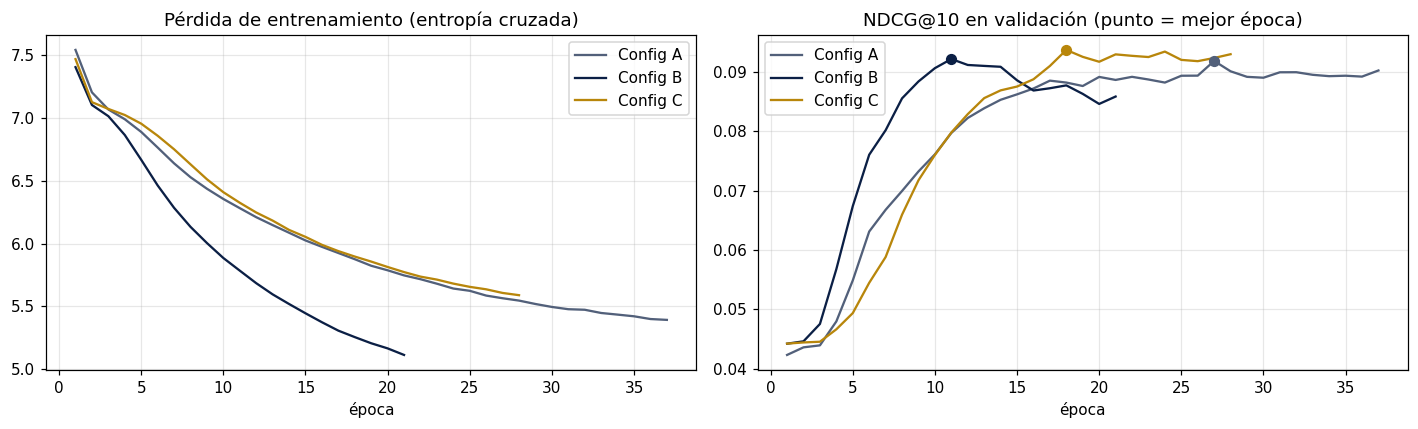

In [18]:
# Curvas por época: pérdida de entrenamiento y NDCG@10 de validación
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for (n, h), c in zip(historias.items(), [GRIS, AZUL, DORADO]):
    ax[0].plot(h["época"], h["pérdida"], color=c, label=f"Config {n}")
    ax[1].plot(h["época"], h["NDCG@10 val"], color=c, label=f"Config {n}")
    mejor = h["NDCG@10 val"].idxmax()
    ax[1].scatter(h.loc[mejor, "época"], h.loc[mejor, "NDCG@10 val"], color=c, s=40, zorder=3)
ax[0].set_title("Pérdida de entrenamiento (entropía cruzada)"); ax[0].set_xlabel("época")
ax[1].set_title("NDCG@10 en validación (punto = mejor época)"); ax[1].set_xlabel("época")
for a in ax:
    a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.show()

### Lectura del entrenamiento de SASRec

- Las tres configuraciones superan con claridad a las líneas base en validación: NDCG@10 entre 0,092 y 0,094, contra 0,065 de las reglas. **Importa más usar la secuencia que la arquitectura exacta**: entre A y C hay solo un 2 % de diferencia.
- **B se sobreajusta.** Es la que más baja la pérdida de entrenamiento (5,2), pero su NDCG de validación tiene el máximo en la época 11 y después cae. La parada temprana la detuvo en la época 21 y recuperó los pesos de la época 11.
- **C es la elegida** (NDCG@10 val = 0,0937, mejor época 18). Tiene la misma arquitectura que B (d = 64, 2 bloques, 2 cabezas) con dropout 0,5. Con una base tan dispersa, regularizar más rinde más que achicar el modelo (A, d = 32).
- El entrenamiento es barato: entre 29 y 44 s por configuración en una GPU T4 de Colab.
- **Recorte declarado:** con `LARGO_MAX` = 14, al 3,7 % de los usuarios se le deja fuera el inicio de su historial.

## 5. Comparación en el conjunto de prueba (se reporta una sola vez)

In [19]:
objetivos_prueba = [prueba[u][1] for u in usuarios]
resultados, rankings_prueba, costo = {}, {}, {}

for nombre, rec in [("Popularidad", rec_popularidad), ("Reglas (lift)", rec_reglas), ("Ítem–ítem coseno", rec_itemitem)]:
    t0 = time.perf_counter()
    (m, pos), rk = evaluar(rec, prueba)
    costo[nombre] = {"inferencia (ms/usuario)": 1000 * (time.perf_counter() - t0) / len(usuarios)}
    resultados[nombre], rankings_prueba[nombre] = m, rk

t0 = time.perf_counter()
rk = rankings_sasrec(sasrec, prueba)
costo["SASRec"] = {"inferencia (ms/usuario)": 1000 * (time.perf_counter() - t0) / len(usuarios)}
resultados["SASRec"], _ = metricas(rk, objetivos_prueba)
rankings_prueba["SASRec"] = rk

# Cobertura: fracción del catálogo que aparece en algún top-10
for n in resultados:
    resultados[n]["Cobertura@10"] = len({i for l in rankings_prueba[n] for i in l[:10]}) / N_ITEMS

tabla = pd.DataFrame(resultados).T
cols = [f"{m}@{k}" for k in KS for m in ["HR", "NDCG", "MRR"]] + ["Cobertura@10"]
tabla[cols].style.format("{:.4f}").highlight_max(color="#d6e4f0")

,HR@5,NDCG@5,MRR@5,HR@10,NDCG@10,MRR@10,HR@20,NDCG@20,MRR@20,Cobertura@10
Popularidad,0.0595,0.0401,0.0337,0.0936,0.0511,0.0383,0.1319,0.0606,0.0408,0.0075
Reglas (lift),0.0941,0.0630,0.0528,0.1328,0.0754,0.0578,0.1652,0.0834,0.0599,0.2155
Ítem–ítem coseno,0.0761,0.0509,0.0426,0.1136,0.0628,0.0474,0.1677,0.0765,0.0511,0.9929
SASRec,0.1158,0.0798,0.0680,0.1740,0.0984,0.0756,0.2419,0.1155,0.0802,0.4085


In [20]:
# Costo: tiempo de entrenamiento, parámetros e inferencia
costo["Popularidad"].update({"entrenamiento (s)": 0.0, "parámetros": N_ITEMS})
costo["Reglas (lift)"].update({"entrenamiento (s)": t_reglas, "parámetros": len(reglas_ar)})
costo["Ítem–ítem coseno"].update({"entrenamiento (s)": t_sim, "parámetros": N_ITEMS * N_ITEMS})
costo["SASRec"].update({"entrenamiento (s)": tiempos[MEJOR_CFG], "parámetros": n_parametros(sasrec)})
tabla_costo = pd.DataFrame(costo).T[["parámetros", "entrenamiento (s)", "inferencia (ms/usuario)"]]
tabla_costo["NDCG@10 prueba"] = tabla["NDCG@10"]
tabla_costo

,parámetros,entrenamiento (s),inferencia (ms/usuario),NDCG@10 prueba
Popularidad,2125.0000,0.0000,0.5706,0.0511
Reglas (lift),1792.0000,126.7733,0.0225,0.0754
Ítem–ítem coseno,4515625.0000,0.4711,0.0813,0.0628
SASRec,187520.0000,40.2900,0.1053,0.0984


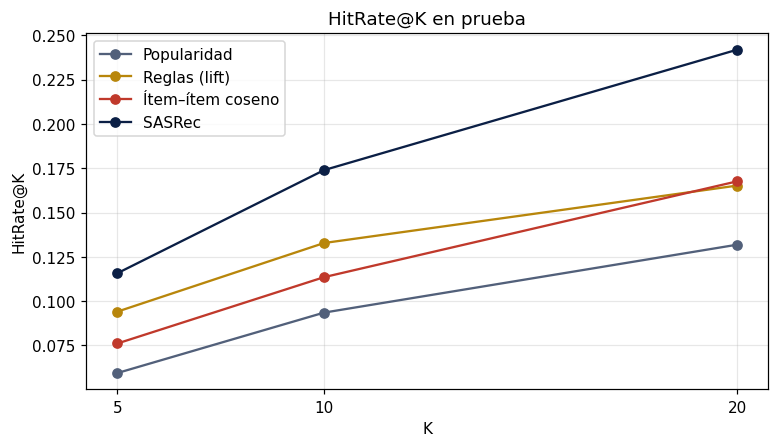

In [21]:
fig, ax = plt.subplots(figsize=(8, 4.2))
colores = {"Popularidad": GRIS, "Reglas (lift)": DORADO, "Ítem–ítem coseno": ROJO, "SASRec": AZUL}
for n, c in colores.items():
    ax.plot(KS, [resultados[n][f"HR@{k}"] for k in KS], marker="o", color=c, label=n)
ax.set_xticks(KS); ax.set_xlabel("K"); ax.set_ylabel("HitRate@K"); ax.grid(alpha=0.3); ax.legend()
ax.set_title("HitRate@K en prueba")
plt.show()

### 5.1 Segmentos: historial corto/largo y perfume popular/cola larga

In [22]:
largo_hist = np.array([len(prueba[u][0]) for u in usuarios])
corte_largo = np.median(largo_hist)
populares_set = set(conteo_entren.index[: int(0.2 * N_ITEMS)])            # 20 % más reseñado
obj_popular = np.array([o in populares_set for o in objetivos_prueba])

segmentos = {
    f"Historial corto (≤ {corte_largo:.0f})": largo_hist <= corte_largo,
    f"Historial largo (> {corte_largo:.0f})": largo_hist > corte_largo,
    "Perfume oculto popular (top 20 %)": obj_popular,
    "Perfume oculto de cola larga": ~obj_popular,
}
filas = []
for seg, mascara in segmentos.items():
    fila = {"segmento": seg, "usuarios": int(mascara.sum())}
    for n in resultados:
        rk = [r for r, m in zip(rankings_prueba[n], mascara) if m]
        ob = [o for o, m in zip(objetivos_prueba, mascara) if m]
        fila[n] = metricas(rk, ob)[0]["NDCG@10"]
    filas.append(fila)
pd.DataFrame(filas).set_index("segmento").style.format({n: "{:.4f}" for n in resultados}).highlight_max(axis=1, subset=list(resultados), color="#d6e4f0")

,usuarios,Popularidad,Reglas (lift),Ítem–ítem coseno,SASRec
segmento,,,,,
Historial corto (≤ 5),3304,0.0540,0.0772,0.0630,0.0990
Historial largo (> 5),2094,0.0466,0.0724,0.0626,0.0974
Perfume oculto popular (top 20 %),3064,0.0900,0.1212,0.0863,0.1599
Perfume oculto de cola larga,2334,0.0000,0.0152,0.0321,0.0177


### 5.2 Tres usuarios: historial, recomendación y pesos de atención

**Cómo se calculan los pesos (declarado).** Se muestran los pesos de atención del **último bloque**, en la **última
posición** (la que predice el próximo perfume), **promediados entre las cabezas** (`average_attn_weights=True`). Es una
simplificación: cada cabeza puede mirar perfumes distintos y el primer bloque también influye. Se leen como "en qué
perfumes se fijó más el modelo", no como una explicación causal completa.


Usuario 3533 | perfume oculto: MOSCHINO · Uomo? Moschino by Moschino for Men 4.2 o
  Historial (antiguo → reciente):
     0.21  Halloween · Halloween Perfumes Shot Men's Edt Spray,
     0.10  Salvatore Ferragamo · F by Ferragamo Black By Salvatore Ferrag
     0.18  ARMAF · ARMAF TRES NUIT 3.4 EAU DE TOILETTE SPRA
     0.26  Nautica · Nautica Voyage by Nautica Eau De Toilett
     0.15  Al Haramain · Al Haramain L'Aventure for Men Eau de Pa
     0.09  Reyane Tradition · Reyane Tradition Insurrection (Dark II)
  Top-5 SASRec: ['Armaf · Armaf Club de Nuit Man Eau de Toilette S', 'Reyane Tradition · Insurrection Wild By Reyane Tradition', 'Bentley · Bentley Intense B140408 Eau de Parfum, 3', 'Nautica · Nautica Voyage Eau De Toilette for Men -', 'Armaf · Armaf Derby Club House Blanche EDT Spray']

Usuario 481 | perfume oculto: SixTmoon · Travel Size Perfume Cologne Bottle Refil
  Historial (antiguo → reciente):
     0.34  Estee Lauder · Youth Dew by Estee Lauder for Women - 2.
     0.29  To

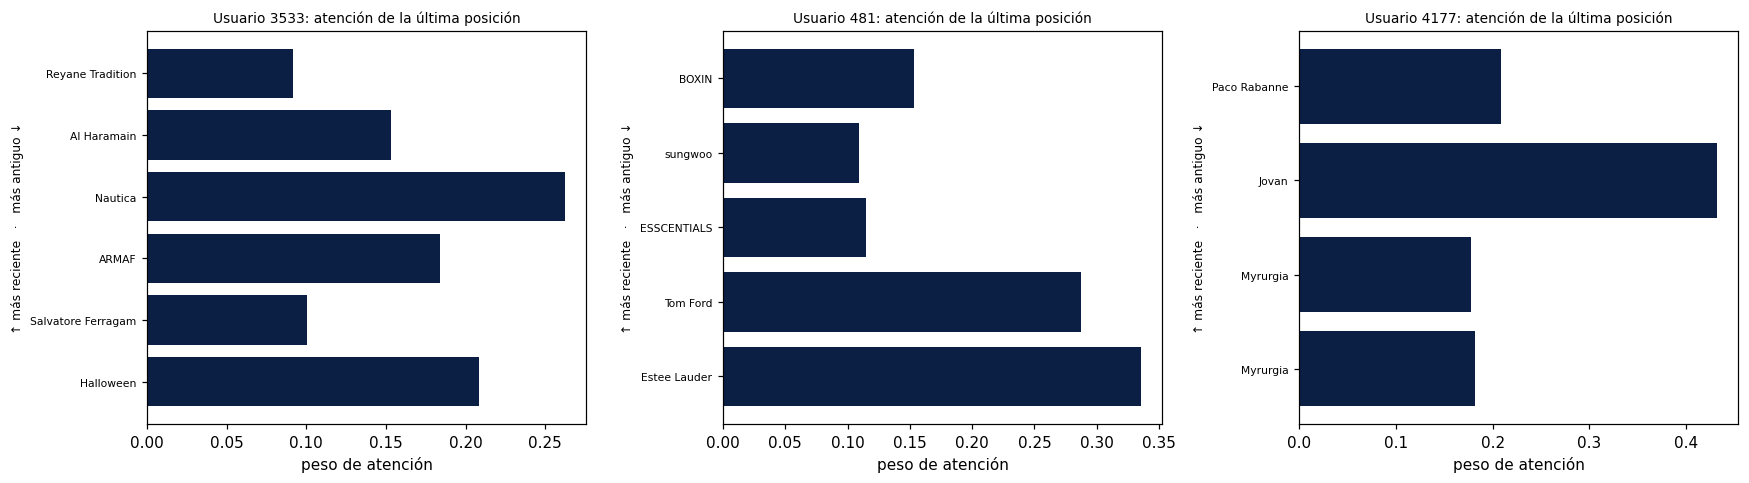

In [23]:
def nombre(i):
    a = idx2item[i]
    return f"{atributos.loc[a, 'marca']} · {atributos.loc[a, 'titulo'][:40]}"


@torch.no_grad()
def pesos_atencion(modelo, hist):
    modelo.eval()
    x = torch.tensor([rellenar(hist)], device=DISPOSITIVO)
    modelo.representar(x, guardar_pesos=True)
    w = modelo.bloques[-1].pesos[0, -1].cpu().numpy()        # fila de la última posición, último bloque
    n = min(len(hist), LARGO_MAX)
    return w[-n:]


rng_u = np.random.default_rng(SEMILLA)
ejemplos = rng_u.choice(len(usuarios), 3, replace=False)
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, f in zip(axs, ejemplos):
    u = usuarios[f]
    hist, obj = prueba[u]
    w = pesos_atencion(sasrec, hist)
    ultimos = hist[-len(w):]
    print(f"\nUsuario {f} | perfume oculto: {nombre(obj)}")
    print("  Historial (antiguo → reciente):")
    for i, p in zip(ultimos[-8:], w[-8:]):
        print(f"    {p:5.2f}  {nombre(i)}")
    print("  Top-5 SASRec:", ["✔ " + nombre(i) if i == obj else nombre(i) for i in rankings_prueba["SASRec"][f][:5]])
    ax.barh(range(len(w)), w, color=AZUL)
    ax.set_yticks(range(len(w)), [marca_de[i][:18] for i in ultimos], fontsize=7)
    ax.set_title(f"Usuario {f}: atención de la última posición", fontsize=9)
    ax.set_xlabel("peso de atención")
    ax.set_ylabel("↑ más reciente   ·   más antiguo ↓", fontsize=8)
plt.tight_layout(); plt.show()

### 5.3 Embeddings de perfumes por categoría

Se proyectan los embeddings aprendidos ($E$) a 2 dimensiones con PCA y se colorean por **género**. Si el modelo aprendió algo
del rubro, perfumes del mismo género deberían quedar cerca aunque nunca se le dijo el género.

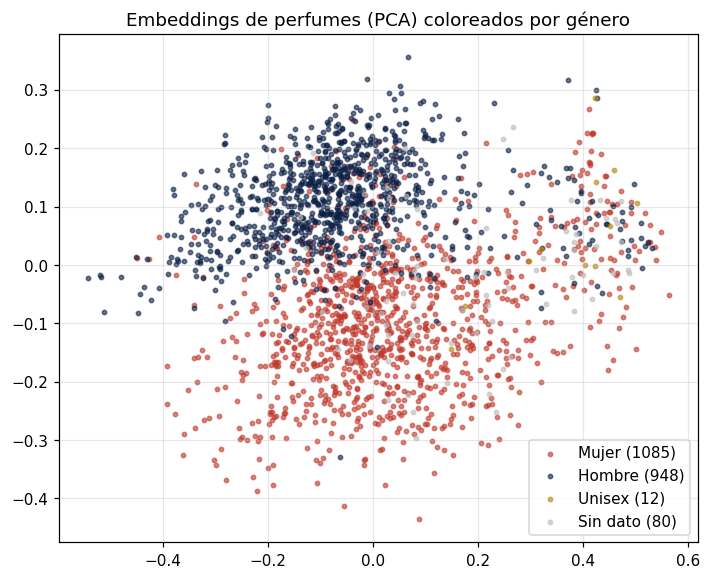

Vecino más cercano del mismo género: 78.9% (al azar se esperaría 49.6%)


In [24]:
E = sasrec.emb_item.weight.detach().cpu().numpy()[1:]        # sin el relleno
E_c = E - E.mean(axis=0)
_, _, Vt = np.linalg.svd(E_c, full_matrices=False)
P = E_c @ Vt[:2].T
gen = np.array([genero_de[i] for i in range(1, N_ITEMS + 1)])

fig, ax = plt.subplots(figsize=(7.5, 6))
for g, c in zip(["Mujer", "Hombre", "Unisex", "Sin dato"], [ROJO, AZUL, DORADO, "#bbbbbb"]):
    m = gen == g
    ax.scatter(P[m, 0], P[m, 1], s=8, alpha=0.6, color=c, label=f"{g} ({m.sum()})")
ax.set_title("Embeddings de perfumes (PCA) coloreados por género"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

# Medida simple: ¿el vecino más cercano en el embedding es del mismo género?
En = E / (np.linalg.norm(E, axis=1, keepdims=True) + 1e-9)
S = En @ En.T; np.fill_diagonal(S, -1)
vecino = S.argmax(axis=1)
validos = gen != "Sin dato"
mismo = (gen[vecino] == gen)[validos].mean()
base_azar = sum((gen[validos] == g).mean() ** 2 for g in set(gen[validos]))
print(f"Vecino más cercano del mismo género: {mismo:.1%} (al azar se esperaría {base_azar:.1%})")

### Lectura de la comparación (prueba, reportada una sola vez)

**Métricas.** SASRec gana en las 9 métricas. HR@10 = **17,4 %** contra 13,3 % de las reglas, 11,4 % de ítem–ítem y 9,4 % de popularidad. Su NDCG@10 = **0,098** es un **31 % más** que la mejor línea base (reglas, 0,075) y casi el doble que popularidad. Los valores absolutos parecen bajos porque cada modelo ordena **los 2.125 perfumes completos**; el paper original evalúa contra 100 negativos al azar, una prueba mucho más fácil.

**Cobertura.** Popularidad recomienda siempre los mismos 16 perfumes (0,8 % del catálogo). Las reglas usan el 22 %, SASRec el **41 %** e ítem–ítem casi todo (99 %), aunque con menos precisión.

**Costo.** SASRec tiene 187.520 parámetros (0,76 MB), entrena en 40 s con GPU y recomienda en 0,11 ms por usuario. Es mucho más liviano que la matriz de ítem–ítem (4,5 millones de valores) y entrena más rápido que el minado de las reglas (127 s).

**Segmentos.**
- *Historial corto vs. largo:* SASRec rinde igual en ambos (NDCG@10 de 0,099 y 0,097). Las reglas son la segunda mejor opción en los dos.
- *Perfume oculto popular:* SASRec domina, con 0,160 contra 0,121 de las reglas.
- *Perfume oculto de cola larga* (43 % de los usuarios): **ahí pierde**. SASRec obtiene 0,018, contra 0,032 de ítem–ítem; las reglas quedan en 0,015. El Transformer aprende bien los caminos frecuentes, pero empuja hacia perfumes conocidos: el **sesgo de popularidad** que advierte el apunte.

**Tres usuarios** (atención promediada entre cabezas, último bloque):
- *Usuario 3533* (Armaf, Nautica, Al Haramain, Reyane): SASRec propone perfumes masculinos del mismo estilo (Club de Nuit, Insurrection Wild, Nautica Voyage). La atención se reparte entre varios perfumes, con su mayor peso en Nautica Voyage (0,26), no solo en el último.
- *Usuario 4177* (Myrurgia Yacht Man, Maja, Jovan Musk, 1 Million): el top 5 incluye **dos variantes de Yacht Man de Myrurgia**, es decir, el modelo reconoce la línea de la marca. La mayor atención va a Jovan Musk (0,43).
- *Usuario 481:* pasa de perfumes de lujo (Youth Dew, Black Orchid) a frascos y atomizadores, y el perfume oculto es otro atomizador. Es alguien que hace *decants*, un patrón muy escaso en la base, y el modelo no lo captura.

**Embeddings.** Sin que el modelo conozca el género, la proyección PCA separa los perfumes de mujer y de hombre. El vecino más cercano de cada perfume es del mismo género el **78,9 %** de las veces, contra 49,6 % esperado al azar: el modelo aprendió estructura real del rubro solo a partir de las secuencias.

## Conclusión: ¿vale la pena el Transformer en este rubro?

**Sí, para la mayoría de los casos, con una salvedad.**

- **A favor.** SASRec mejora en 31 % el NDCG@10 de la mejor línea base (reglas ajustadas en validación) y casi duplica a la popularidad. Lo logra con un modelo de menos de 1 MB que entrena en menos de un minuto y recomienda en 0,1 ms. La exploración mostró que el orden tiene información (los perfumes consecutivos comparten marca 1,35 veces más que al azar), y el Transformer es el único modelo que la usa de forma aprendida y no con una regla fija. Además, aprendió sin supervisión la separación por género.
- **En contra.** En los perfumes de **cola larga** rinde peor que ítem–ítem. Para una tienda de perfumes, que también quiere vender nichos y lanzamientos, eso importa.
- **Recomendación.** Usar SASRec como motor principal y complementarlo con un método que no dependa de la popularidad (ítem–ítem o atributos olfativos) cuando el usuario busca algo fuera de lo popular. Eso se trabaja en la Entrega 2.

**Decisiones declaradas en esta versión:** umbrales de reglas elegidos en validación; atención promediada entre cabezas y solo del último bloque; recorte del historial a los 14 perfumes más recientes (afecta al 3,7 % de los usuarios). Todas las cifras de esta corrida quedan en `data/resumen_corrida.json`, desde donde se construye el informe.

## 6. Exportación para el repositorio

Archivos que pide la Entrega 1: `data/secuencias.parquet`, `data/mapa_items.csv`, `data/metricas.csv` y `modelos/sasrec.pt` (< 100 MB).
Además, **desde esta misma corrida**, se exportan `data/segmentos.csv` y `data/reglas.csv` (los usa el dashboard) y
`data/resumen_corrida.json`, con todas las cifras que cita el informe, para que informe, métricas y modelo salgan de una sola ejecución.

In [25]:
os.makedirs("data", exist_ok=True)
os.makedirs("modelos", exist_ok=True)

# Secuencias: un usuario anónimo por fila (sin el id de Amazon)
pd.DataFrame({
    "usuario": range(len(usuarios)),
    "items": [secuencias[u] for u in usuarios],
    "fechas": [[str(f.date()) for f in fechas[u]] for u in usuarios],
}).to_parquet("data/secuencias.parquet", index=False)

mapa = atributos.loc[[idx2item[i] for i in range(1, N_ITEMS + 1)]].reset_index().rename(columns={"index": "parent_asin"})
mapa.insert(0, "idx", range(1, N_ITEMS + 1))
mapa["reseñas_entrenamiento"] = mapa["idx"].map(conteo_entren).fillna(0).astype(int)
mapa.to_csv("data/mapa_items.csv", index=False)

tabla.join(tabla_costo.drop(columns="NDCG@10 prueba")).to_csv("data/metricas.csv")
pd.DataFrame(filas).to_csv("data/segmentos.csv", index=False)
pd.DataFrame({"antecedente": reglas_ar["antecedents"].apply(lambda x: next(iter(x))),
              "consecuente": reglas_ar["consequents"].apply(lambda x: next(iter(x))),
              "soporte": reglas_ar["support"], "confianza": reglas_ar["confidence"],
              "lift": reglas_ar["lift"]}).sort_values("lift", ascending=False).to_csv("data/reglas.csv", index=False)

# Resumen de ESTA corrida: todas las cifras que cita el informe salen de aquí
def _a_json(x):
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (np.floating,)):
        return float(x)
    if isinstance(x, pd.DataFrame):
        return json.loads(x.to_json(orient="records", force_ascii=False))
    if isinstance(x, pd.Series):
        return json.loads(x.to_json(force_ascii=False))
    return str(x)


resumen_corrida = {
    "semilla": SEMILLA, "dispositivo": str(DISPOSITIVO), "torch": torch.__version__,
    "rondas_5core": RONDAS_5CORE, "base": resumen,
    "genero": atributos["genero"].value_counts(), "marcas": atributos["marca"].nunique(),
    "con_precio": float(atributos["precio"].notna().mean()),
    "densidad": densidad, "largo": {"media": float(largos.mean()), "mediana": float(largos.median()),
                                    "max": int(largos.max()), "p95": LARGO_MAX, "recortados": recortados},
    "top20_concentra": float(top20), "periodo": [str(datos["fecha"].min().date()), str(datos["fecha"].max().date())],
    "evidencia_orden": evidencia, "verificacion_manual": VERIF,
    "itemitem": {"ultimos": MEJOR_L, "decaimiento": MEJOR_D, "segundos": t_sim},
    "reglas": {"soporte_canastas": MEJOR_SOP, "confianza": MEJOR_CONF, "n_reglas": len(reglas_ar),
               "segundos": t_reglas, "grilla": grilla_reglas},
    "validacion_lineas_base": {"Popularidad": m_pop_val, "Reglas": m_ar_val},
    "sasrec_configs": tabla_cfg, "sasrec_elegida": MEJOR_CFG, "historias": {n: h for n, h in historias.items()},
    "prueba": tabla, "costo": tabla_costo, "segmentos": pd.DataFrame(filas),
    "ejemplos_usuarios": [int(e) for e in ejemplos],
    "embeddings": {"mismo_genero": float(mismo), "azar": float(base_azar)},
}
with open("data/resumen_corrida.json", "w", encoding="utf-8") as f:
    json.dump(resumen_corrida, f, ensure_ascii=False, indent=1, default=_a_json)

torch.save({"estado": sasrec.state_dict(), "config": CONFIGS[MEJOR_CFG], "n_items": N_ITEMS,
            "largo_max": LARGO_MAX}, "modelos/sasrec.pt")

for ruta in ["data/secuencias.parquet", "data/mapa_items.csv", "data/metricas.csv", "data/segmentos.csv",
             "data/reglas.csv", "data/resumen_corrida.json", "modelos/sasrec.pt"]:
    print(f"{ruta:28s} {os.path.getsize(ruta) / 1e6:6.2f} MB")

data/secuencias.parquet        0.19 MB
data/mapa_items.csv            0.24 MB
data/metricas.csv              0.00 MB
data/segmentos.csv             0.00 MB
data/reglas.csv                0.11 MB
data/resumen_corrida.json      0.02 MB
modelos/sasrec.pt              0.76 MB


In [26]:
# En Colab: comprimir para descargar y subir a GitHub
if "google.colab" in sys.modules:
    import shutil
    from google.colab import files
    shutil.make_archive("entrega1_archivos", "zip", ".", "data")
    shutil.make_archive("entrega1_modelo", "zip", ".", "modelos")
    files.download("entrega1_archivos.zip")
    files.download("entrega1_modelo.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>